# Capstone worked example: exploratory analysis of a clinical study

## Learning objectives

By the end of this notebook you will be able to:

- clean a raw clinical dataset and document each decision
- derive analysis variables
- describe participants and outcomes with summary tables
- communicate findings with clear figures
- interpret results and state limitations

## Introduction

A complete worked solution to the capstone brief in `README.md`. It follows the stages in order:
understand, import, explore, clean, derive, describe, visualise, interpret, export.

The data are simulated for teaching. The patterns found here describe these data only.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW = Path("../datasets/raw")
PROCESSED = Path("../datasets/processed")
FIGURES = Path("figures")
PROCESSED.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
ARM_ORDER = ["Usual care", "Diet", "Diet + exercise"]
ARM_COLOURS = dict(zip(ARM_ORDER, sns.color_palette("colorblind", 3)))

def save(fig, name):
    """Save a figure as PNG (300 dpi) in the figures folder."""
    fig.savefig(FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

`ARM_COLOURS` fixes one colour per arm, used in every figure so readers can follow the arms throughout.

## 1. Understanding the data

Each row should be **one participant**: baseline characteristics, baseline measurements and six-month
measurements. The questions are in the README: who the participants are, whether the arms are
comparable at baseline, how blood pressure and glucose changed by arm, who was lost to follow-up, and
how the variables relate.

## 2. Import

In [2]:
raw = pd.read_csv(RAW / "clinic_study.csv", parse_dates=["baseline_date"])
print(raw.shape)
raw.head()

(486, 13)


,participant,clinic,sex,age_years,arm,baseline_date,weight_kg,height_m,sbp_baseline,glucose_baseline,smoking,sbp_6m,glucose_6m
0,HC-001,East,Male,67.0,Usual care,2024-11-08,90.0,1.54,161.0,5.4,current,154.0,5.0
1,HC-002,North,Male,33.0,Usual care,2024-04-04,78.1,1.55,134.0,8.1,never,NaN,NaN
2,HC-003,east,Male,62.0,Usual care,2024-05-21,87.5,1.85,165.0,5.6,unknown,165.0,6.9
3,HC-004,West,Male,72.0,Diet + exercise,2024-03-20,91.8,1.77,141.0,7.6,never,135.0,6.4
4,HC-005,East,Female,40.0,Diet + exercise,2024-03-16,69.2,1.76,147.0,6.0,never,127.0,4.7


## 3. Exploration

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   participant       486 non-null    str           
 1   clinic            486 non-null    str           
 2   sex               486 non-null    str           
 3   age_years         486 non-null    float64       
 4   arm               486 non-null    str           
 5   baseline_date     486 non-null    datetime64[us]
 6   weight_kg         486 non-null    float64       
 7   height_m          486 non-null    float64       
 8   sbp_baseline      486 non-null    float64       
 9   glucose_baseline  486 non-null    float64       
 10  smoking           486 non-null    str           
 11  sbp_6m            451 non-null    float64       
 12  glucose_6m        451 non-null    float64       
dtypes: datetime64[us](1), float64(7), str(5)
memory usage: 63.9 KB


In [4]:
raw.describe().round(2)

,age_years,baseline_date,weight_kg,height_m,sbp_baseline,glucose_baseline,sbp_6m,glucose_6m
count,486.00,486,486.00,486.00,486.00,486.00,451.00,451.00
mean,50.64,2024-06-25 15:51:06.666666,81.83,3.04,142.11,7.42,137.66,7.00
min,-1.00,2024-02-02 00:00:00,47.90,1.43,102.00,0.90,81.00,1.30
25%,35.00,2024-04-09 00:00:00,73.50,1.61,133.00,6.40,127.00,5.90
50%,50.00,2024-06-23 12:00:00,82.50,1.67,142.00,7.50,137.00,6.90
75%,66.00,2024-09-06 18:00:00,89.78,1.74,151.75,8.50,150.00,8.00
max,150.00,2024-11-26 00:00:00,123.60,185.00,177.00,13.80,185.00,13.70
std,17.77,NaN,12.71,15.07,13.88,1.62,16.78,1.75


In [5]:
for col in ["clinic", "sex", "arm", "smoking"]:
    print(col, raw[col].map(repr).value_counts().to_dict(), "\n")

clinic {"'North'": 155, "'East'": 152, "'West'": 139, "'east'": 23, "'West '": 17} 

sex {"'Male'": 205, "'Female'": 199, "'M'": 32, "'F'": 31, "'female'": 19} 

arm {"'Diet + exercise'": 170, "'Usual care'": 158, "'Diet'": 158} 

smoking {"'never'": 276, "'former'": 117, "'current'": 65, "'unknown'": 28} 



`map(repr)` shows each value in quotes, so stray spaces are visible.

In [6]:
print("fully duplicated rows:", raw.duplicated().sum())
print("repeated IDs:", raw["participant"].duplicated().sum())
print("ages outside 18-100:", raw.loc[~raw["age_years"].between(18, 100), "age_years"].tolist())
print("heights above 3 m:", raw.loc[raw["height_m"] > 3, "height_m"].tolist())
print("missing values:", raw.isna().sum()[raw.isna().sum() > 0].to_dict())

fully duplicated rows: 6
repeated IDs: 6
ages outside 18-100: [0.0, 0.0, -1.0, 150.0, -1.0]
heights above 3 m: [155.0, 154.0, 177.0, 185.0]
missing values: {'sbp_6m': 35, 'glucose_6m': 35}


### Problems found

| # | problem | evidence |
|---|---|---|
| 1 | duplicated rows | 6 rows repeat another row exactly |
| 2 | clinic spelled inconsistently | `east`, and `West ` with a trailing space |
| 3 | sex coded five ways | Male, Female, M, F, female |
| 4 | impossible ages | 0, −1 and 150 |
| 5 | some heights in centimetres | values of 154 to 185 in a column of metres |
| 6 | no six-month values for some participants | 35 missing in both `sbp_6m` and `glucose_6m` |

The arm and smoking columns are consistent. `unknown` is a real smoking category, recorded as such,
not a missing value to fill.

## 4. Cleaning

Each step changes a copy and is checked straight away.

In [7]:
df = raw.copy()

# 1. duplicates
df = df.drop_duplicates()
assert df["participant"].is_unique

# 2. clinic
df["clinic"] = df["clinic"].str.strip().str.title()

# 3. sex
df["sex"] = df["sex"].str.strip().str.lower().map({"male": "Male", "m": "Male", "female": "Female", "f": "Female"})
assert df["sex"].notna().all()

print(len(raw), "->", len(df), "rows")
print(df["clinic"].value_counts().to_dict(), df["sex"].value_counts().to_dict())

486 -> 480 rows
{'East': 173, 'West': 154, 'North': 153} {'Female': 245, 'Male': 235}


**Ages (problem 4).** Ages of 0, −1 and 150 cannot be corrected from the data (the true age is
unknown), so they are set to missing. The participants stay in the dataset, because their other
measurements are valid.

In [8]:
bad_age = ~df["age_years"].between(18, 100)
print(df.loc[bad_age, ["participant", "age_years"]])
df.loc[bad_age, "age_years"] = np.nan

    participant  age_years
6        HC-007        0.0
317      HC-318        0.0
388      HC-389       -1.0
425      HC-426      150.0
445      HC-446       -1.0


**Heights (problem 5).** Values above 3 can only be centimetres (all are 1.5-1.9 m once divided by
100), so they are converted rather than discarded.

In [9]:
cm = df["height_m"] > 3
print(df.loc[cm, ["participant", "height_m"]])
df.loc[cm, "height_m"] = df.loc[cm, "height_m"] / 100
assert df["height_m"].between(1.3, 2.2).all()

    participant  height_m
6        HC-007     155.0
93       HC-094     154.0
107      HC-108     177.0
472      HC-473     185.0


**Six-month values (problem 6).** Missing follow-up is not an error to fix: these participants did not
return. They are kept, and flagged so they can be compared with those who did.

**Types.** Text columns with a fixed set of values become ordered categories so that tables and
figures follow a sensible order.

In [10]:
df["arm"] = pd.Categorical(df["arm"], categories=ARM_ORDER, ordered=True)
df["smoking"] = pd.Categorical(df["smoking"], categories=["never", "former", "current", "unknown"], ordered=True)
df.dtypes

participant                    str
clinic                         str
sex                            str
age_years                  float64
arm                       category
baseline_date       datetime64[us]
weight_kg                  float64
height_m                   float64
sbp_baseline               float64
glucose_baseline           float64
smoking                   category
sbp_6m                     float64
glucose_6m                 float64
dtype: object

### Cleaning log

| problem | decision | rows affected |
|---|---|---|
| duplicated rows | removed | 6 |
| clinic spelling | stripped spaces, title case | 39 |
| sex codes | mapped to Male / Female | 81 |
| impossible ages | set to missing | 5 |
| heights in cm | divided by 100 | 4 |
| no six-month values | kept; flagged as not completed | 35 |

In [11]:
print("clinic changed:", (raw.drop_duplicates()["clinic"] != df["clinic"]).sum())
print("sex changed:   ", (raw.drop_duplicates()["sex"] != df["sex"]).sum())

clinic changed: 39
sex changed:    81


## 5. Derived variables

In [12]:
df["bmi"] = (df["weight_kg"] / df["height_m"] ** 2).round(1)
df["bmi_class"] = pd.cut(df["bmi"], [0, 18.5, 25, 30, 100], right=False,
                         labels=["Underweight", "Normal", "Overweight", "Obese"])
df["age_group"] = pd.cut(df["age_years"], [18, 35, 50, 65, 101], right=False,
                         labels=["18-34", "35-49", "50-64", "65+"])
df["completed"] = df["sbp_6m"].notna() & df["glucose_6m"].notna()
df["sbp_change"] = df["sbp_6m"] - df["sbp_baseline"]
df["glucose_change"] = (df["glucose_6m"] - df["glucose_baseline"]).round(2)
df["hypertensive_baseline"] = df["sbp_baseline"] >= 140

df[["participant", "bmi", "bmi_class", "age_group", "completed", "sbp_change", "glucose_change"]].head()

,participant,bmi,bmi_class,age_group,completed,sbp_change,glucose_change
0,HC-001,37.9,Obese,65+,True,-7.0,-0.4
1,HC-002,32.5,Obese,18-34,False,NaN,NaN
2,HC-003,25.6,Overweight,50-64,True,0.0,1.3
3,HC-004,29.3,Overweight,65+,True,-6.0,-1.2
4,HC-005,22.3,Normal,35-49,True,-20.0,-1.3


## 6. Descriptive statistics

### Table 1: participant characteristics by arm

A "Table 1" describes who is in each group. With random allocation the arms should look similar;
large differences would complicate any comparison of outcomes.

In [13]:
def mean_sd(s):
    return f"{s.mean():.1f} ({s.std():.1f})"

def n_pct(s, value):
    return f"{(s == value).sum()} ({(s == value).mean() * 100:.0f}%)"

def describe_group(g):
    return pd.Series({
        "N": f"{len(g)}",
        "Age, years: mean (SD)": mean_sd(g["age_years"]),
        "Female: n (%)": n_pct(g["sex"], "Female"),
        "BMI: mean (SD)": mean_sd(g["bmi"]),
        "Current smoker: n (%)": n_pct(g["smoking"], "current"),
        "SBP, mmHg: mean (SD)": mean_sd(g["sbp_baseline"]),
        "SBP ≥ 140: n (%)": n_pct(g["hypertensive_baseline"], True),
        "Glucose, mmol/L: mean (SD)": mean_sd(g["glucose_baseline"]),
    })

table1 = pd.concat({arm: describe_group(g) for arm, g in df.groupby("arm", observed=True)}, axis=1)
table1["All"] = describe_group(df)
table1

,Usual care,Diet,Diet + exercise,All
N,158,155,167,480
"Age, years: mean (SD)",50.0 (16.6),51.5 (16.8),50.9 (16.7),50.8 (16.7)
Female: n (%),75 (47%),82 (53%),88 (53%),245 (51%)
BMI: mean (SD),29.8 (5.3),29.1 (5.4),29.6 (5.6),29.5 (5.4)
Current smoker: n (%),23 (15%),14 (9%),26 (16%),63 (13%)
"SBP, mmHg: mean (SD)",142.4 (14.1),141.8 (13.2),142.4 (14.2),142.2 (13.8)
SBP ≥ 140: n (%),91 (58%),88 (57%),95 (57%),274 (57%)
"Glucose, mmol/L: mean (SD)",7.6 (1.7),7.4 (1.6),7.3 (1.6),7.4 (1.6)


The arms are similar in size and in age, sex, BMI, smoking and baseline measurements, as expected from
random allocation. Mean baseline systolic blood pressure is around 142 mmHg, and more than half of the
participants start at or above 140.

### Table 2: outcomes in participants who completed follow-up

In [14]:
completers = df[df["completed"]]
table2 = completers.groupby("arm", observed=True).agg(
    n=("participant", "size"),
    sbp_baseline=("sbp_baseline", "mean"),
    sbp_6m=("sbp_6m", "mean"),
    sbp_change=("sbp_change", "mean"),
    sbp_change_sd=("sbp_change", "std"),
    glucose_baseline=("glucose_baseline", "mean"),
    glucose_6m=("glucose_6m", "mean"),
    glucose_change=("glucose_change", "mean"),
    glucose_change_sd=("glucose_change", "std"),
).round(2)
table2

,n,sbp_baseline,sbp_6m,sbp_change,sbp_change_sd,glucose_baseline,glucose_6m,glucose_change,glucose_change_sd
arm,,,,,,,,,
Usual care,145,142.73,142.19,-0.54,8.12,7.54,7.56,0.03,0.58
Diet,140,141.67,138.27,-3.40,7.99,7.41,6.99,-0.42,0.57
Diet + exercise,160,142.43,133.38,-9.05,8.04,7.33,6.53,-0.80,0.54


A rough 95% confidence interval for each mean change (mean ± 1.96 × SD / √n) gives a sense of
precision:

In [15]:
ci = completers.groupby("arm", observed=True)[["sbp_change", "glucose_change"]].agg(["mean", "sem"])
for col in ["sbp_change", "glucose_change"]:
    ci[(col, "low")] = ci[(col, "mean")] - 1.96 * ci[(col, "sem")]
    ci[(col, "high")] = ci[(col, "mean")] + 1.96 * ci[(col, "sem")]
ci.round(2)

sbp_change       glucose_change       sbp_change        \
                      mean   sem           mean   sem        low  high   
arm                                                                      
Usual care           -0.54  0.67           0.03  0.05      -1.87  0.78   
Diet                 -3.40  0.68          -0.42  0.05      -4.72 -2.08   
Diet + exercise      -9.05  0.64          -0.80  0.04     -10.30 -7.80   

                glucose_change        
                           low  high  
arm                                   
Usual care               -0.07  0.12  
Diet                     -0.52 -0.33  
Diet + exercise          -0.89 -0.72

### Table 3: who completed follow-up?

In [16]:
follow = df.groupby("completed").agg(
    n=("participant", "size"),
    age=("age_years", "mean"),
    pct_female=("sex", lambda s: (s == "Female").mean() * 100),
    bmi=("bmi", "mean"),
    sbp_baseline=("sbp_baseline", "mean"),
    glucose_baseline=("glucose_baseline", "mean"),
).round(1)
follow.index = follow.index.map({True: "completed", False: "not completed"})
print(pd.crosstab(df["arm"], df["completed"], margins=True))
follow

completed        False  True  All
arm                              
Usual care          13   145  158
Diet                15   140  155
Diet + exercise      7   160  167
All                 35   445  480


,n,age,pct_female,bmi,sbp_baseline,glucose_baseline
completed,,,,,,
not completed,35,52.6,48.6,30.3,141.3,7.6
completed,445,50.7,51.2,29.4,142.3,7.4


## 7. Visualisations

### Figure 1: who are the participants?

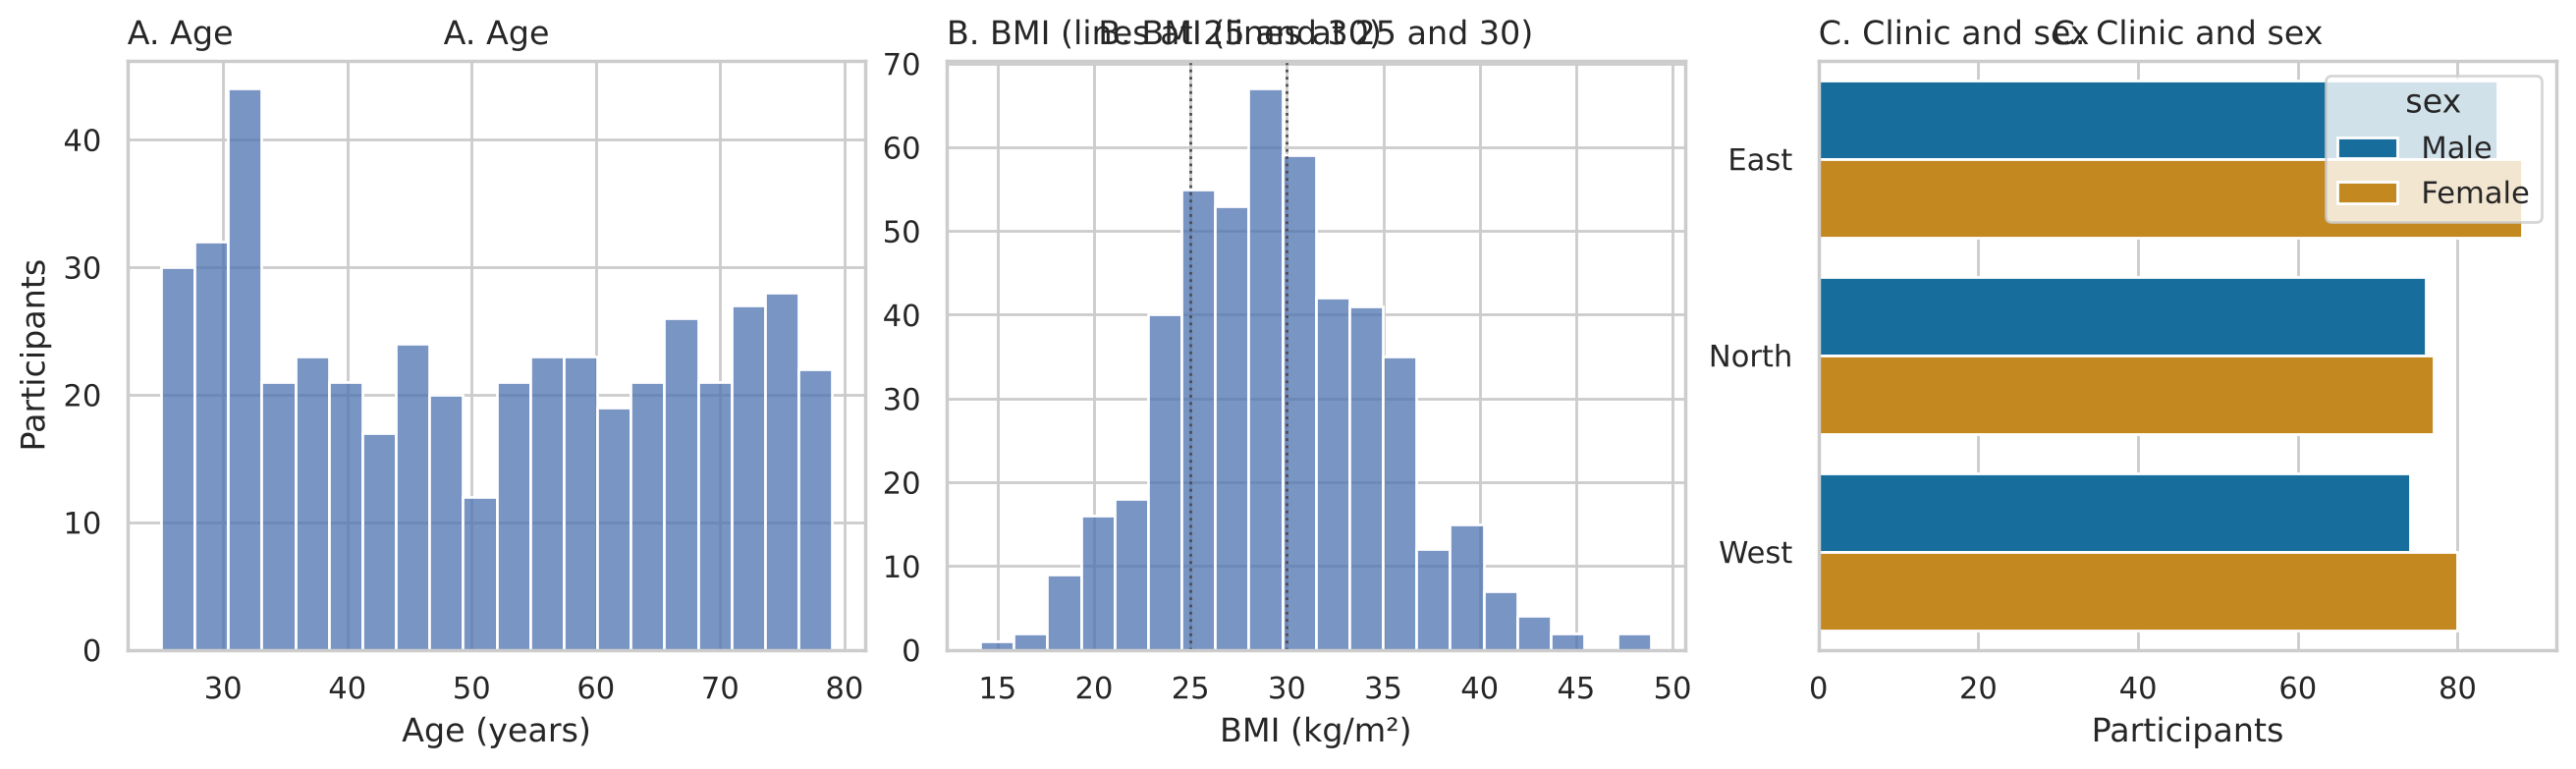

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
sns.histplot(data=df, x="age_years", bins=20, ax=axes[0])
axes[0].set(xlabel="Age (years)", ylabel="Participants", title="A. Age")
sns.histplot(data=df, x="bmi", bins=20, ax=axes[1])
for cut in (25, 30):
    axes[1].axvline(cut, color="0.3", linestyle=":", linewidth=1)
axes[1].set(xlabel="BMI (kg/m²)", ylabel="", title="B. BMI (lines at 25 and 30)")
sns.countplot(data=df, y="clinic", hue="sex", palette="colorblind", ax=axes[2])
axes[2].set(xlabel="Participants", ylabel="", title="C. Clinic and sex")
for ax in axes:
    ax.set_title(ax.get_title(), loc="left")
save(fig, "fig1_participants")
plt.show()

### Figure 2: baseline comparison of the arms

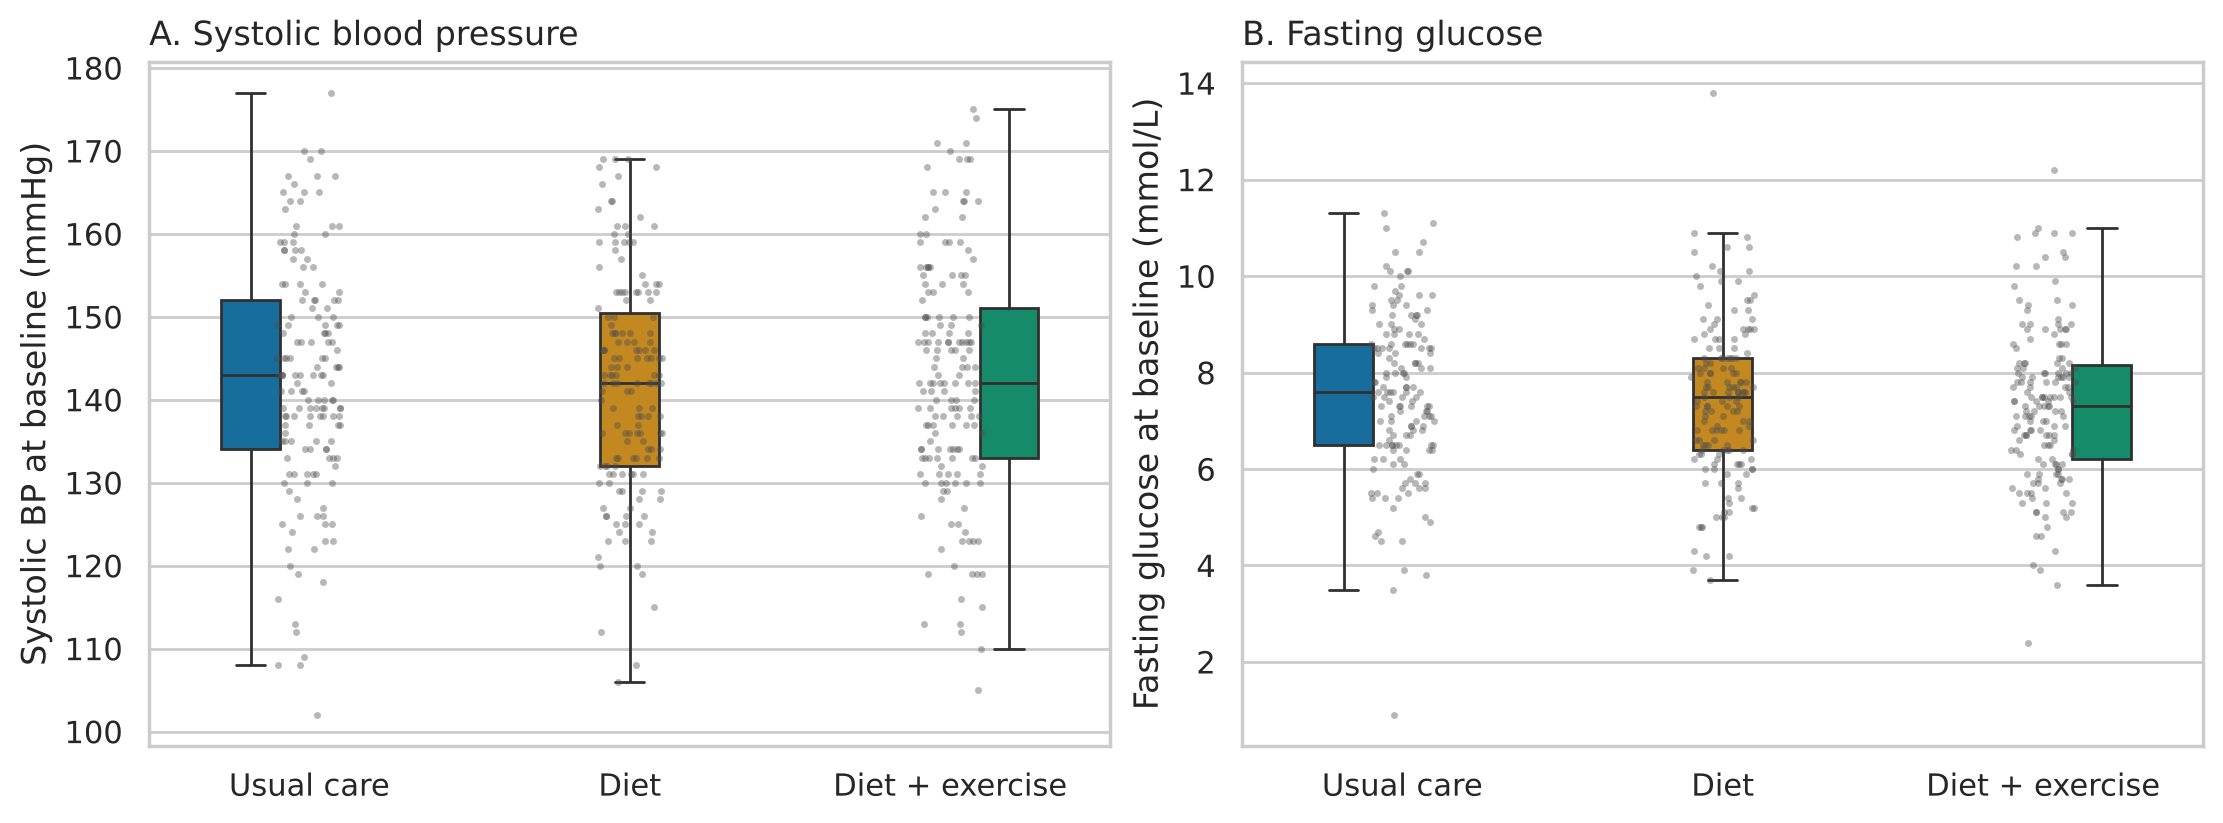

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, col, label in [(axes[0], "sbp_baseline", "Systolic BP at baseline (mmHg)"),
                       (axes[1], "glucose_baseline", "Fasting glucose at baseline (mmol/L)")]:
    sns.boxplot(data=df, x="arm", y=col, hue="arm", palette=ARM_COLOURS, showfliers=False, width=0.55, ax=ax)
    sns.stripplot(data=df, x="arm", y=col, color="0.3", size=2.5, alpha=0.4, ax=ax)
    ax.set(xlabel="", ylabel=label)
axes[0].set_title("A. Systolic blood pressure", loc="left")
axes[1].set_title("B. Fasting glucose", loc="left")
save(fig, "fig2_baseline_by_arm")
plt.show()

### Figure 3: change over six months by arm

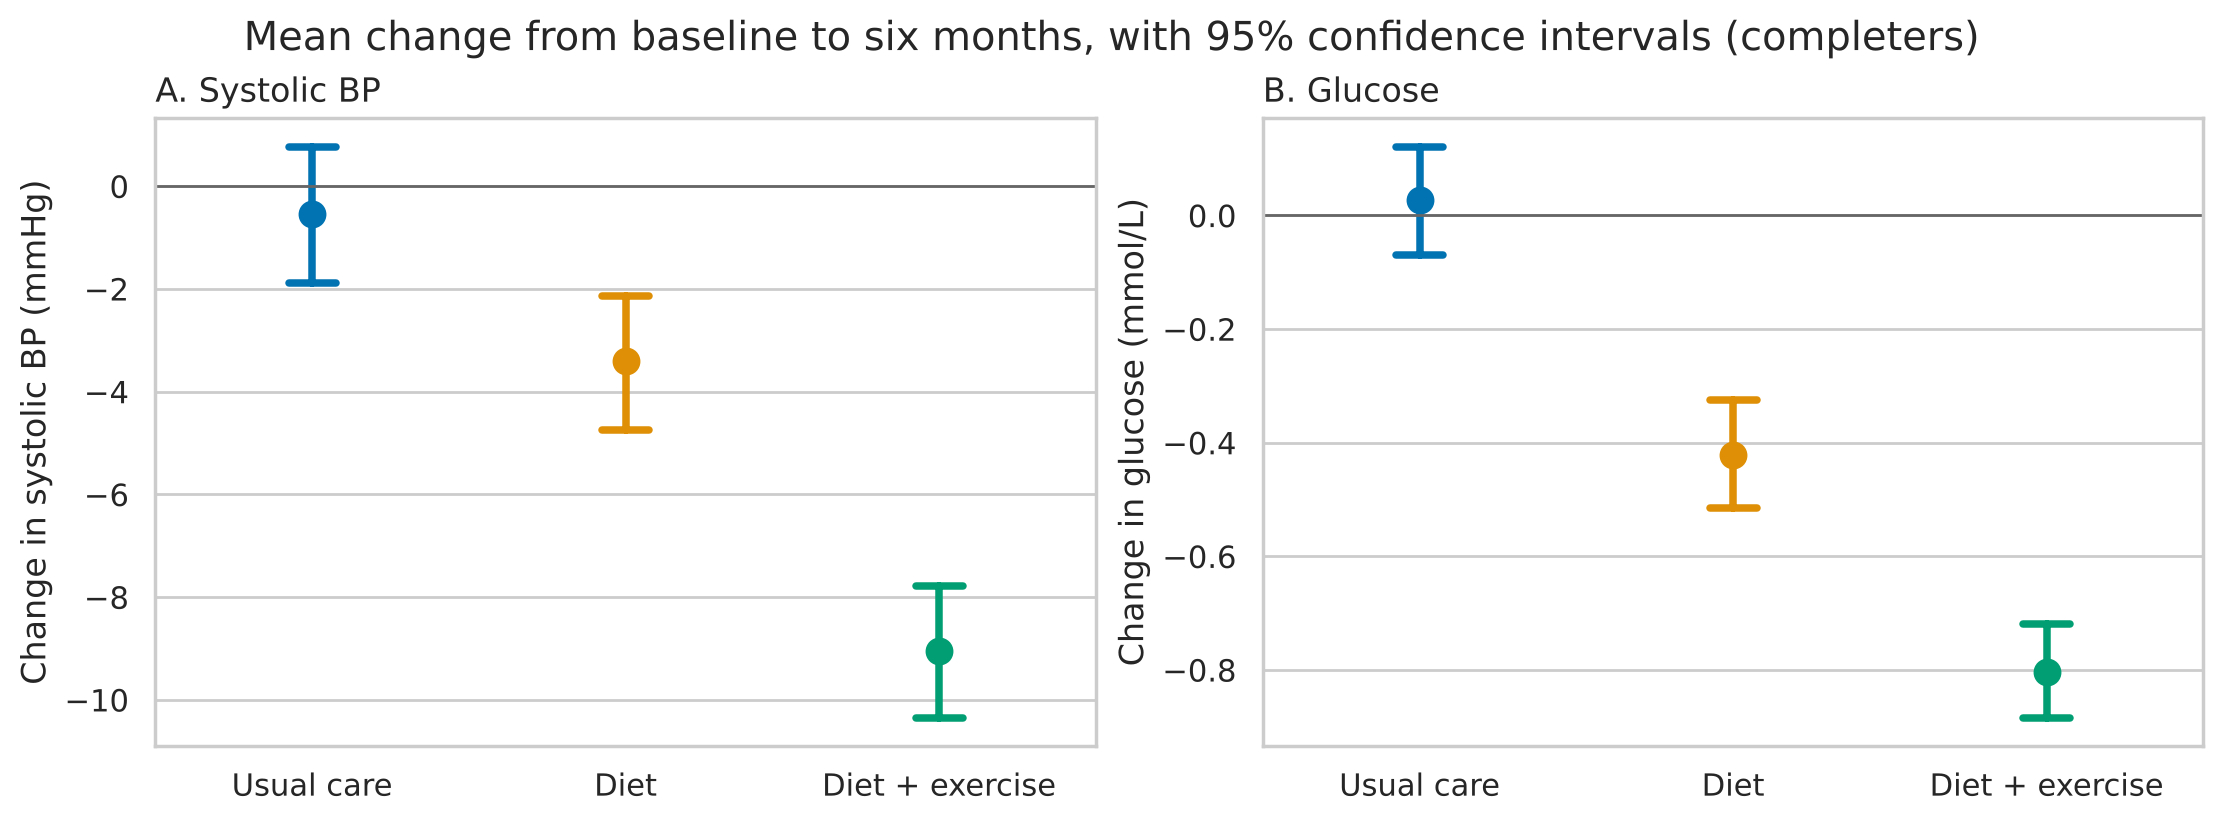

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, col, label in [(axes[0], "sbp_change", "Change in systolic BP (mmHg)"),
                       (axes[1], "glucose_change", "Change in glucose (mmol/L)")]:
    sns.pointplot(data=completers, x="arm", y=col, hue="arm", palette=ARM_COLOURS,
                  errorbar=("ci", 95), capsize=0.15, markersize=8, ax=ax)
    ax.axhline(0, color="0.4", linewidth=1)
    ax.set(xlabel="", ylabel=label)
axes[0].set_title("A. Systolic BP", loc="left")
axes[1].set_title("B. Glucose", loc="left")
fig.suptitle("Mean change from baseline to six months, with 95% confidence intervals (completers)")
save(fig, "fig3_change_by_arm")
plt.show()

### Figure 4: individual changes in blood pressure

Means hide how much individuals vary. Each line is one participant, from baseline to six months; the
thick line is the arm mean.

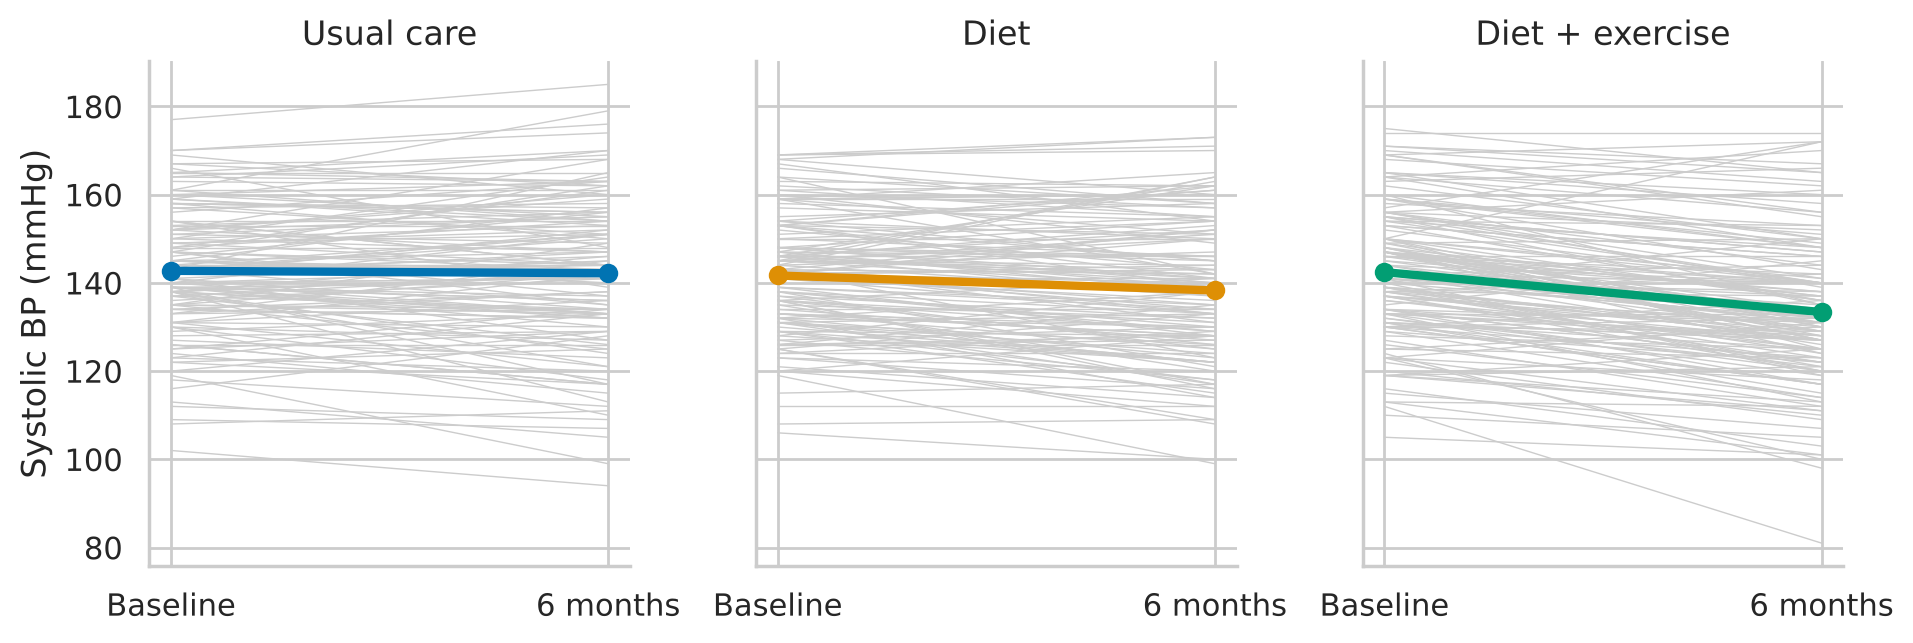

In [20]:
long = completers.melt(id_vars=["participant", "arm"], value_vars=["sbp_baseline", "sbp_6m"],
                       var_name="time", value_name="sbp")
long["time"] = long["time"].map({"sbp_baseline": "Baseline", "sbp_6m": "6 months"})

g = sns.FacetGrid(long, col="arm", col_order=ARM_ORDER, height=3.6, aspect=0.9, sharey=True)
g.map_dataframe(sns.lineplot, x="time", y="sbp", units="participant", estimator=None,
                color="0.8", linewidth=0.5)
for ax, arm in zip(g.axes.flat, ARM_ORDER):
    m = long[long["arm"] == arm].groupby("time", sort=False)["sbp"].mean()
    ax.plot(m.index, m.values, color=ARM_COLOURS[arm], linewidth=3, marker="o")
g.set_titles("{col_name}")
g.set_axis_labels("", "Systolic BP (mmHg)")
save(g.figure, "fig4_individual_sbp")
plt.show()

### Figure 5: relationships between variables

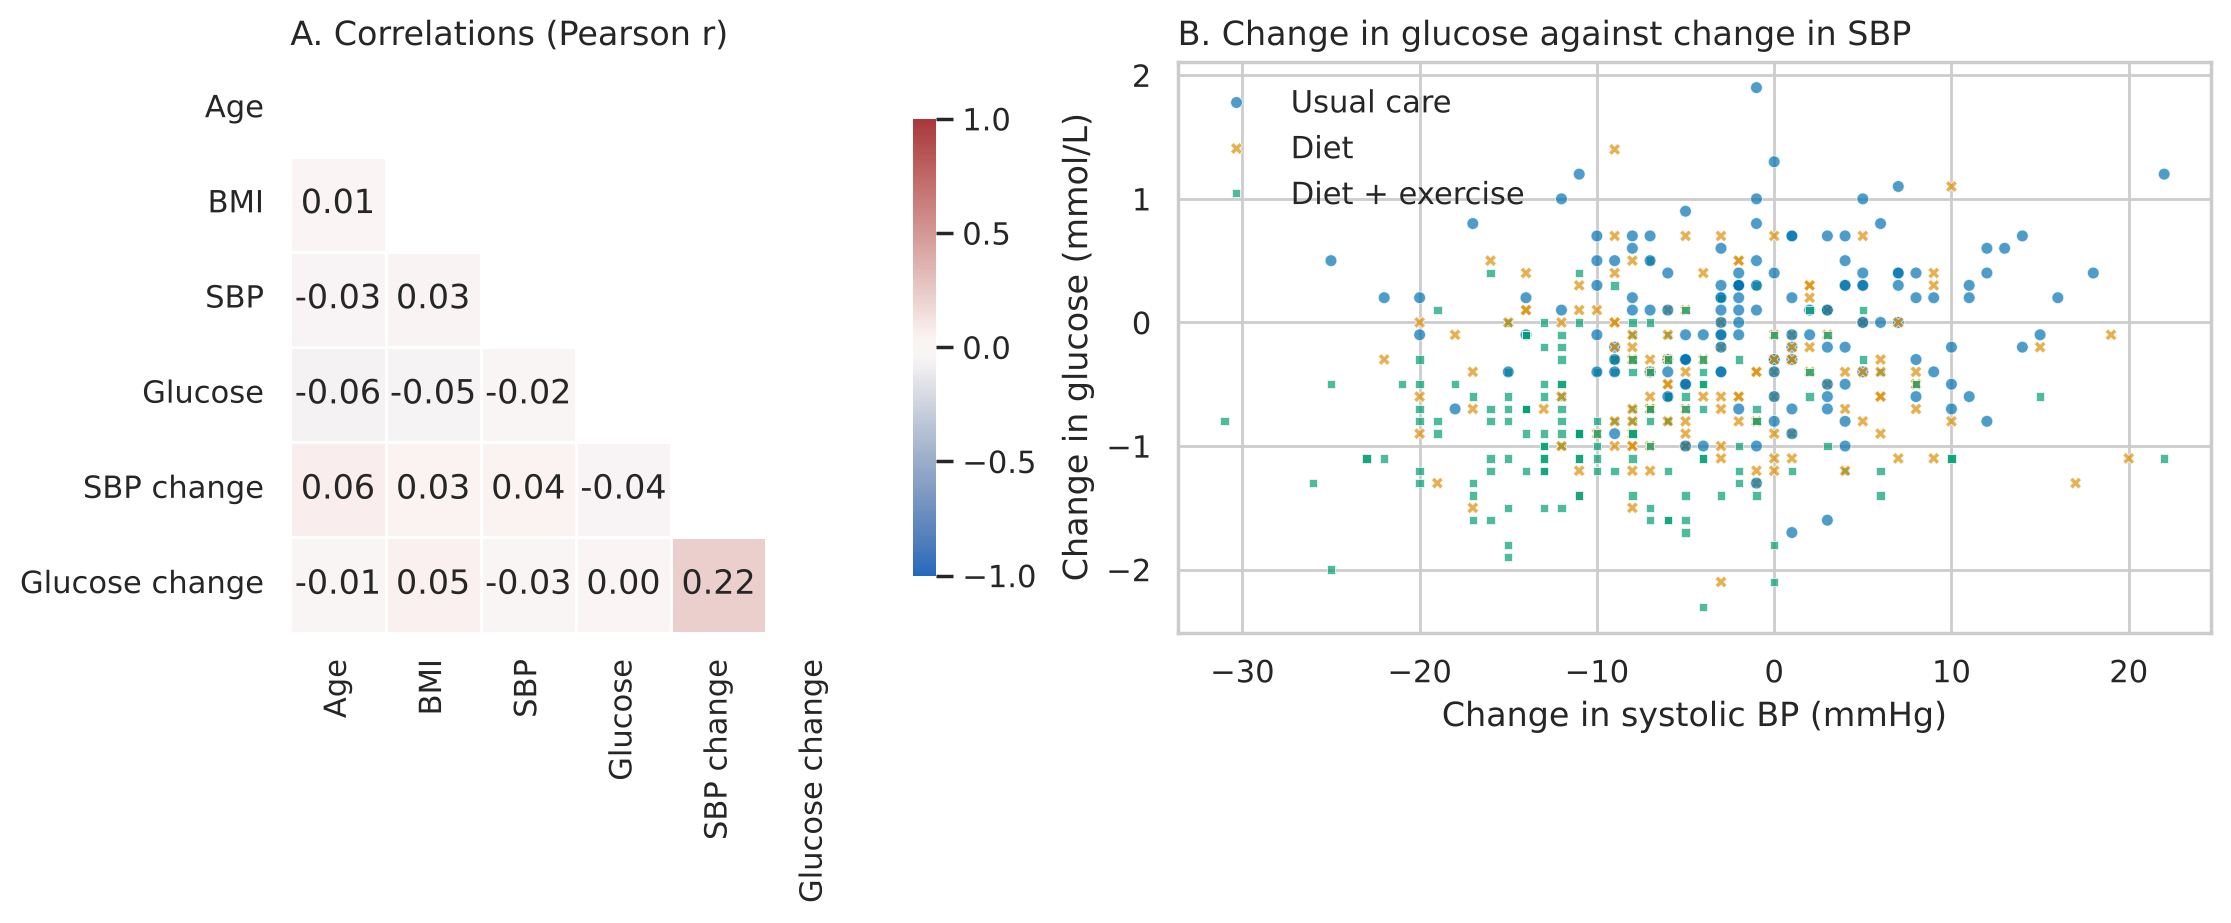

In [21]:
cols = {"age_years": "Age", "bmi": "BMI", "sbp_baseline": "SBP", "glucose_baseline": "Glucose",
        "sbp_change": "SBP change", "glucose_change": "Glucose change"}
corr = df[list(cols)].rename(columns=cols).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[0])
axes[0].set_title("A. Correlations (Pearson r)", loc="left")
axes[0].grid(False)
sns.scatterplot(data=completers, x="sbp_change", y="glucose_change", hue="arm", style="arm",
                palette=ARM_COLOURS, hue_order=ARM_ORDER, s=18, alpha=0.7, ax=axes[1])
axes[1].set(xlabel="Change in systolic BP (mmHg)", ylabel="Change in glucose (mmol/L)")
axes[1].set_title("B. Change in glucose against change in SBP", loc="left")
axes[1].legend(title=None, frameon=False)
save(fig, "fig5_relationships")
plt.show()

### Figure 6: loss to follow-up

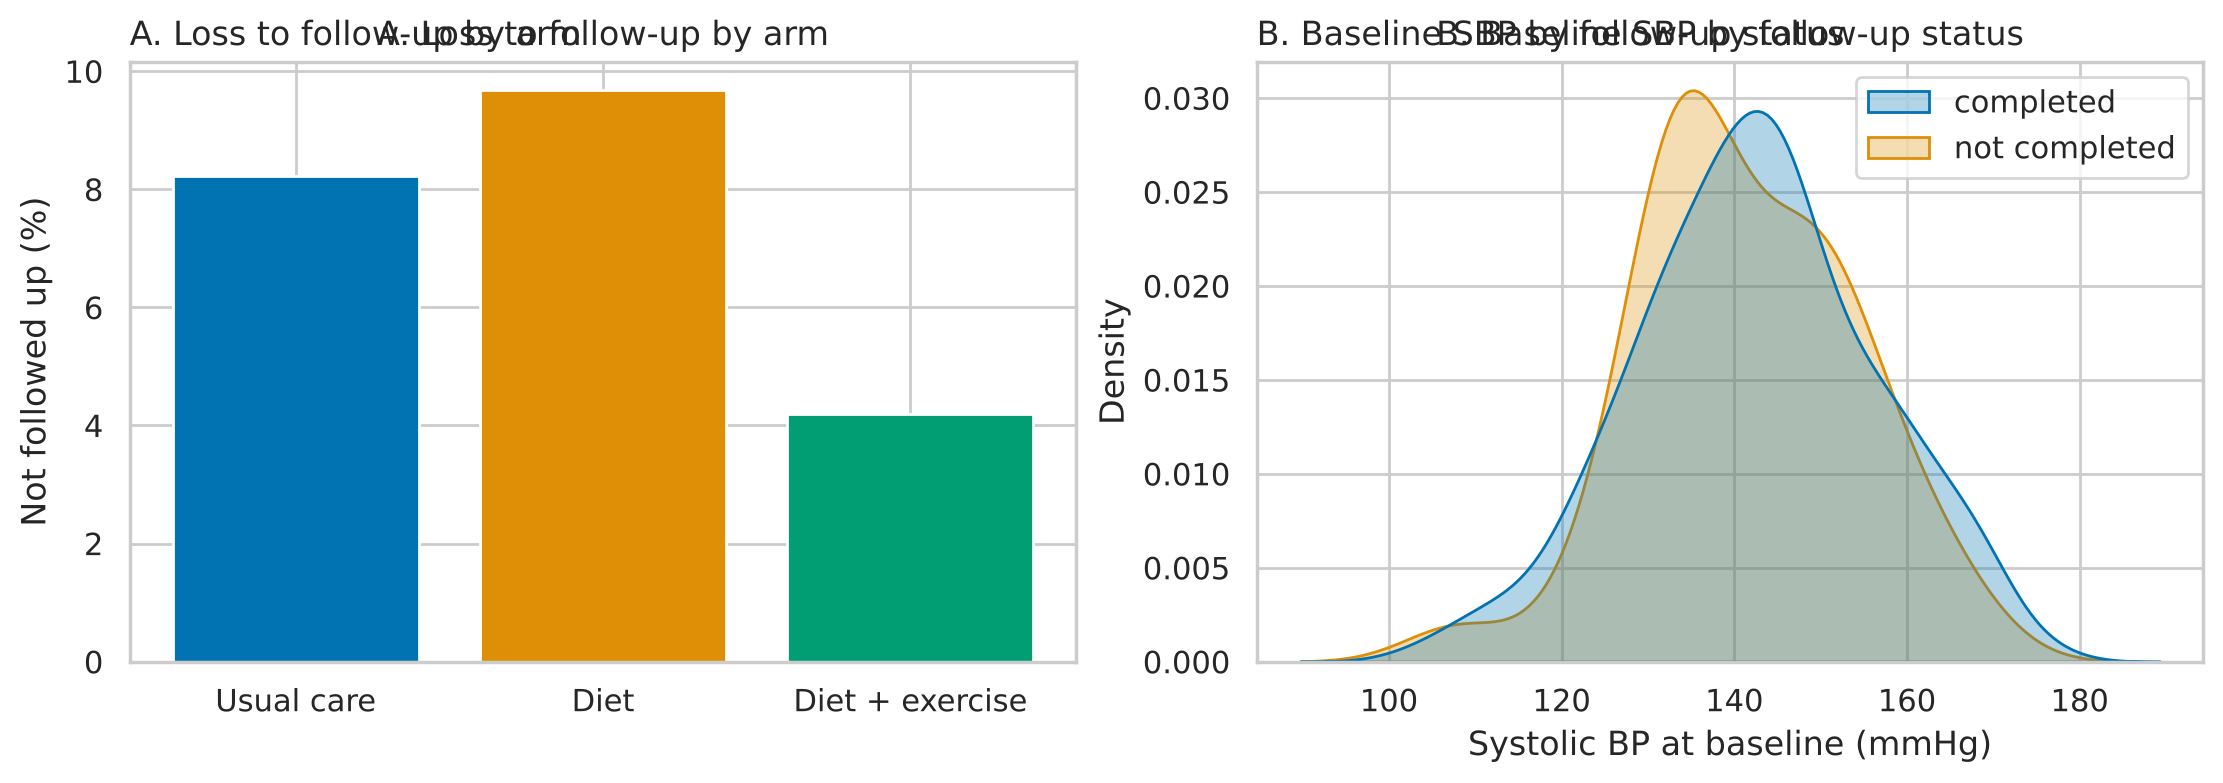

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
rate = (1 - df.groupby("arm", observed=True)["completed"].mean()) * 100
axes[0].bar(rate.index, rate.values, color=[ARM_COLOURS[a] for a in rate.index])
axes[0].set(ylabel="Not followed up (%)", title="A. Loss to follow-up by arm")
sns.kdeplot(data=df, x="sbp_baseline", hue=df["completed"].map({True: "completed", False: "not completed"}),
            common_norm=False, fill=True, alpha=0.3, palette="colorblind", ax=axes[1])
axes[1].set(xlabel="Systolic BP at baseline (mmHg)", title="B. Baseline SBP by follow-up status")
axes[1].get_legend().set_title(None)
for ax in axes:
    ax.set_title(ax.get_title(), loc="left")
save(fig, "fig6_follow_up")
plt.show()

In [23]:
sorted(p.name for p in FIGURES.glob("*.png"))

['fig1_participants.png',
 'fig2_baseline_by_arm.png',
 'fig3_change_by_arm.png',
 'fig4_individual_sbp.png',
 'fig5_relationships.png',
 'fig6_follow_up.png']

## 8. Findings

In [24]:
n = len(df); n_comp = int(df["completed"].sum())
chg = completers.groupby("arm", observed=True)[["sbp_change", "glucose_change"]].mean()
r_changes = completers["sbp_change"].corr(completers["glucose_change"])
r_within = completers.groupby("arm", observed=True)[["sbp_change", "glucose_change"]].corr().xs("sbp_change", level=1)["glucose_change"]
print(f"{n} participants; {n_comp} ({n_comp / n:.0%}) completed follow-up")
print(chg.round(2))
print(f"SBP change vs glucose change: r = {r_changes:.2f} overall; within arms:", r_within.round(2).to_dict())

480 participants; 445 (93%) completed follow-up
                 sbp_change  glucose_change
arm                                        
Usual care            -0.54            0.03
Diet                  -3.40           -0.42
Diet + exercise       -9.05           -0.80
SBP change vs glucose change: r = 0.22 overall; within arms: {'Usual care': 0.01, 'Diet': -0.01, 'Diet + exercise': 0.05}


**1. Participants.** After removing six duplicate rows, the study has 480 participants across three
clinics, with a broad adult age range and roughly equal numbers of men and women. Average BMI is in the
overweight range, and baseline systolic blood pressure averages about 142 mmHg (Table 1, Figure 1).

**2. Baseline comparability.** The three arms are similar in age, sex, BMI, smoking, blood pressure
and glucose at baseline (Table 1, Figure 2), so differences at six months are unlikely to come from
differences in who was in each arm.

**3. Change over six months.** Among completers, systolic blood pressure barely changed under *Usual
care* (mean −0.5 mmHg; the 95% confidence interval includes zero), fell by about 3 mmHg in the *Diet*
arm and by about 9 mmHg in the *Diet + exercise* arm (Table 2, Figure 3A). Glucose followed the same
order: essentially no change under usual care, a fall of about 0.4 mmol/L with diet, and about
0.8 mmol/L with diet and exercise (Figure 3B). None of the three arms' confidence intervals overlap for
either outcome. Figure 4 shows that individual changes still vary widely within every arm: some
participants' blood pressure rose even in the arm with the largest average fall.

**4. Follow-up.** 35 participants (7%) have no six-month measurements. Fewer were lost from the
*Diet + exercise* arm (7 of 167, 4%) than from the other two (8-10%) (Figure 6A). Those who did not
return look similar to completers at baseline (Table 3, Figure 6B), which makes serious bias from loss
to follow-up less likely, though it cannot be ruled out.

**5. Relationships.** The baseline variables are almost unrelated to each other in these data: all
their correlations are close to zero (Figure 5A). The one clear correlation is between the two
*changes* (r about 0.2): participants whose blood pressure fell more also tended to have larger falls in
glucose. But within each arm this correlation disappears (r close to 0). It arises only because both
outcomes fall most in the *Diet + exercise* arm and least under usual care, so the arms form three
clusters (Figure 5B). This is the same lesson as Simpson's paradox in module 8: always check whether a
grouping variable explains an overall correlation.

### Limitations

- the data are **simulated** for teaching; real studies are messier and effects smaller
- the analysis is **descriptive**: the differences between arms would need a formal statistical test
  (for example, a regression of six-month SBP on arm, adjusted for baseline) before drawing conclusions
- outcome comparisons use **completers only**; methods for missing data are beyond this course
- five implausible ages were set to missing and four heights converted from centimetres; other errors
  that look plausible cannot be detected
- six months is a short follow-up; whether changes last is unknown

## 9. Export

In [25]:
export_cols = ["participant", "clinic", "sex", "age_years", "age_group", "arm", "baseline_date",
               "weight_kg", "height_m", "bmi", "bmi_class", "smoking",
               "sbp_baseline", "sbp_6m", "sbp_change", "glucose_baseline", "glucose_6m", "glucose_change",
               "hypertensive_baseline", "completed"]
df[export_cols].to_csv(PROCESSED / "clinic_study_clean.csv", index=False)
table1.to_csv(PROCESSED / "clinic_study_table1.csv")
table2.to_csv(PROCESSED / "clinic_study_table2.csv")

check = pd.read_csv(PROCESSED / "clinic_study_clean.csv")
print(check.shape)
check.head(3)

(480, 20)


,participant,clinic,sex,age_years,age_group,arm,baseline_date,weight_kg,height_m,bmi,bmi_class,smoking,sbp_baseline,sbp_6m,sbp_change,glucose_baseline,glucose_6m,glucose_change,hypertensive_baseline,completed
0,HC-001,East,Male,67.0,65+,Usual care,2024-11-08,90.0,1.54,37.9,Obese,current,161.0,154.0,-7.0,5.4,5.0,-0.4,True,True
1,HC-002,North,Male,33.0,18-34,Usual care,2024-04-04,78.1,1.55,32.5,Obese,never,134.0,NaN,NaN,8.1,NaN,NaN,False,False
2,HC-003,East,Male,62.0,50-64,Usual care,2024-05-21,87.5,1.85,25.6,Overweight,unknown,165.0,165.0,0.0,5.6,6.9,1.3,True,True


The cleaned dataset, the two summary tables and six figures are now saved. Rerunning this notebook
from the raw file reproduces all of them exactly.

## Further reading

- The brief: `README.md` in this folder
- [STROBE checklist for reporting observational studies](https://www.strobe-statement.org/)
- [Seaborn: visualising statistical relationships](https://seaborn.pydata.org/tutorial/relational.html)